### 1. Exploración Inicial de Fuentes de Datos
Inspección preliminar de la estructura, columnas y tipos de datos de los archivos crudos alojados en `data/raw/`.



### 2. Diagnóstico de Calidad de Datos: Presupuestos 2025
Se detecta que los encabezados reales se encuentran en la fila `0` y existe una columna vacía (`Unnamed: 0`), lo que requerirá limpieza antes del cruce de tablas.

In [1]:
import pandas as pd

df=pd.read_csv('../data/raw/Comparacion_peliculas_2025.csv')

df

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3
0,NaN,Película,Presupuesto (USD),Fuente
1,NaN,A Minecraft Movie,"$ 150,000,000.00",https://www.the-numbers.com/movie/Minecraft-Mo...
2,NaN,Five Nights at Freddy's 2,"$ 51,000,000.00",https://www.the-numbers.com/movie/Five-Nights-...
3,NaN,Until Dawn,"$ 15,000,000.00",https://www.the-numbers.com/movie/Until-Dawn-(...
4,NaN,Zootopia 2,"$ 150,000,000.00",https://www.the-numbers.com/movie/Zootopia-2-(...
5,NaN,Lilo & Stitch,"$ 100,000,000.00",https://www.the-numbers.com/movie/Lilo-and-Sti...
6,NaN,How to Train Your Dragon,"$ 150,000,000.00",https://www.the-numbers.com/movie/How-to-Train...
7,NaN,The Bad Guys 2,"$ 80,000,000.00",https://www.the-numbers.com/movie/Bad-Guys-2-T...
8,NaN,Freakier Friday,"$ 42,000,000.00",https://www.the-numbers.com/movie/Freakier-Fri...
9,NaN,Smurfs,"$ 58,000,000.00",https://www.the-numbers.com/movie/Smurfs-(2025)


### 3. Limpieza, Normalización y Cálculo Automatizado de ROI
Se corrigen los encabezados (`header=1`), se cruzan los presupuestos de producción con la recaudación mundial (`Movie_Theater_Box_Office_Revenue_2025 new.csv`), se transforman los montos monetarios a formato numérico (`float`) y se ordena el ranking de rentabilidad (`ROI_Calculado`).

In [2]:
import pandas as pd

# 1. Cargamos los DataFrames
# Al usar header=1, la segunda columna se llama 'Película'
df_presupuestos = pd.read_csv('../data/raw/Comparacion_peliculas_2025.csv', header=1).drop(columns=['Unnamed: 0'])
df_global = pd.read_csv('../data/raw/Movie_Theater_Box_Office_Revenue_2025 new.csv')

# 2. Unimos ambas tablas alineando 'Película' de presupuestos con 'Release Group' de taquilla global
df_roi = pd.merge(df_presupuestos, df_global, left_on='Película', right_on='Release Group')

# 3. Limpiamos las columnas para que sean numéricas antes de calcular el ROI
# Quitamos símbolos de dólar, espacios y comas
df_roi['Presupuesto_Num'] = df_roi['Presupuesto (USD)'].astype(str).str.replace('$', '').str.replace(',', '').str.strip().astype(float)
df_roi['Taquilla_Num'] = df_roi['Worldwide'].astype(str).str.replace('$', '').str.replace(',', '').str.strip().astype(float)

# 4. Calculamos la columna de ROI (Taquilla Total / Presupuesto)
df_roi['ROI_Calculado'] = df_roi['Taquilla_Num'] / df_roi['Presupuesto_Num']

# 5. Ordenamos de mayor a menor ROI
df_roi_ordenado = df_roi.sort_values(by='ROI_Calculado', ascending=False)

# Mostramos las columnas principales del resultado
display(df_roi_ordenado[['Película', 'Presupuesto (USD)', 'Worldwide', 'ROI_Calculado']])

,Película,Presupuesto (USD),Worldwide,ROI_Calculado
11,Ne Zha 2,"$ 80,000,000.00","$2,260,176,370",28.252205
3,Zootopia 2,"$ 150,000,000.00","$1,866,577,771",12.443852
19,The Housemaid,"$ 35,000,000.00","$395,732,105",11.306632
4,Lilo & Stitch,"$ 100,000,000.00","$1,038,027,526",10.380275
17,The Conjuring: Last Rites,"$ 55,000,000.00","$499,156,445",9.075572
23,Weapons,"$ 38,000,000.00","$269,972,492",7.104539
0,A Minecraft Movie,"$ 150,000,000.00","$961,187,780",6.407919
22,Final Destination: Bloodlines,"$ 50,000,000.00","$317,854,739",6.357095
42,The Monkey,"$ 11,000,000.00","$68,871,071",6.261006
34,Materialists,"$ 20,000,000.00","$105,649,413",5.282471


### 4. Exploración Geográfica por Territorio
Análisis del desglose internacional de *A Minecraft Movie*, identificando mercados líderes, recaudación en fin de semana de estreno y errores de traducción en los datos crudos (`Porcelana` → China).

In [3]:
import pandas as pd

df=pd.read_csv('../data/raw/A_minecraft_movie_taquillas.csv')

df

,Id,Territorio,Fecha de lanzamiento,Fin de semana de inauguración,Cines/pantallas\nde estreno,Número máximo\nde pantallas/cines,Compromisos teatrales,Taquilla total,Fecha del informe
0,1,Argentina,4/3/2025,"$3,700,000",0.000,0.000,0.000,"$9,500,000",4/6/2026
1,2,Australia,4/3/2025,"$8,622,478",725.000,731.000,0.000,"$39,793,608",4/6/2026
2,3,Brasil,4/3/2025,"$5,800,000",1.637,1.637,0.000,"$19,200,000",4/4/2026
3,4,Porcelana,4/4/2025,"$12,898,507",0.000,0.000,0.000,$29.200.000,29/09/2026
4,5,Croacia,4/3/2025,"$508,120",144.000,144.000,746.000,$1.501.002,28/10/2026
5,6,República Checa,4/3/2025,$1.855.070,206.000,206.000,1.738,"$7,682,526",28/10/2026
6,7,Finlandia,4/4/2025,$1.299.755,124.000,133.000,1.089,"$5,674,614",30/10/2026
7,8,Francia,4/2/2025,"$5,400,000",775.000,784.000,0.000,$23.000.000,4/4/2026
8,9,Alemania,4/3/2025,"$10,300,000",690.000,760.000,1.378,$39.200.000,4/4/2026
9,10,Italia,4/3/2025,"$5,148,770",0.000,0.000,0.000,$13.300.000,4/4/2026


In [4]:
import pandas as pd
df_box = pd.read_csv('../data/raw/Movie_Theater_Box_Office_Revenue_2025 new.csv')
display(df_box[df_box['Release Group'] == 'A Minecraft Movie'])

,Rank,Release Group,Worldwide,Domestic,%,Foreign,%.1
4,5,A Minecraft Movie,"$961,187,780","$424,087,780",44.1%,"$537,100,000",55.9%


### 5. Distribución Doméstica vs. Internacional
Validación de la participación de mercado de *A Minecraft Movie* ($961,18M totales): **44.1%** en mercado doméstico (EE. UU.) frente a un **55.9%** ($537,1M) en mercados internacionales.

PNG generado correctamente


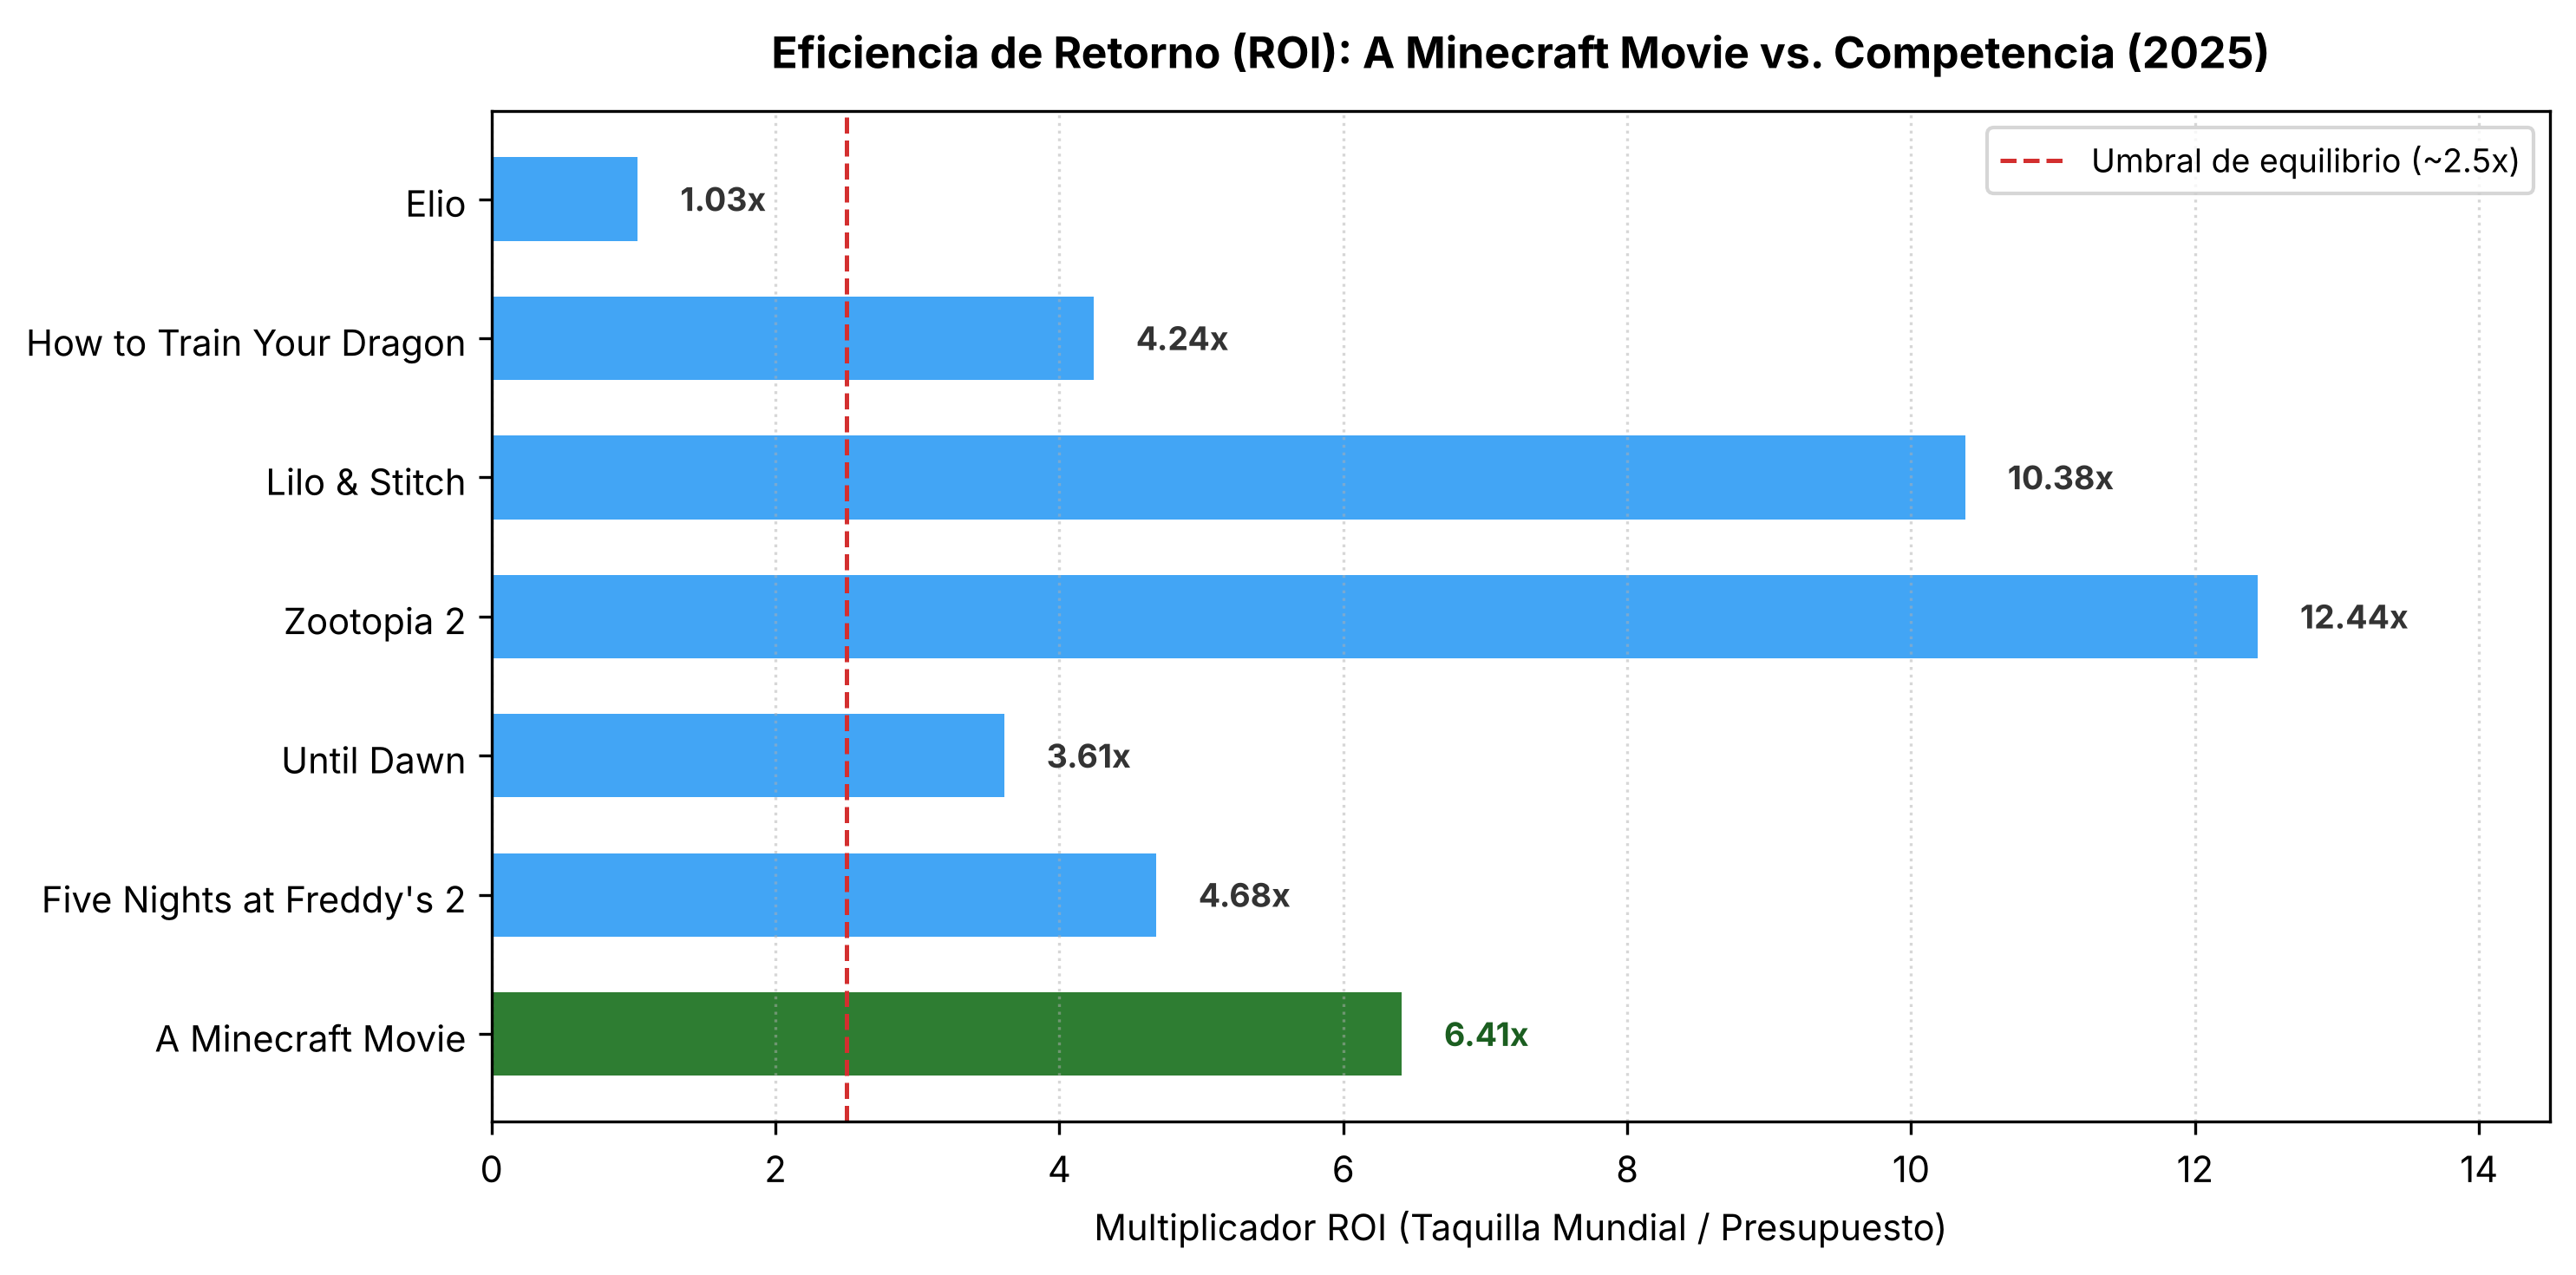

In [5]:
import matplotlib.pyplot as plt

# Datos de películas seleccionadas (Presupuesto en Millones USD y Multiplicador ROI)
peliculas = [
    "A Minecraft Movie",
    "Five Nights at Freddy's 2",
    "Until Dawn",
    "Zootopia 2",
    "Lilo & Stitch",
    "How to Train Your Dragon",
    "Elio"
]
roi_valores = [6.41, 4.68, 3.61, 12.44, 10.38, 4.24, 1.03]

# Configuración de la figura
fig, ax = plt.subplots(figsize=(10, 5), dpi=300)

# Colores: Destacamos en verde el caso central (A Minecraft Movie)
colores = [
    "#2E7D32" if p == "A Minecraft Movie" else "#42A5F5"
    for p in peliculas
]

barras = ax.barh(peliculas, roi_valores, color=colores, height=0.6)

# Línea de equilibrio (umbral estándar de rentabilidad ~2.5x)
ax.axvline(2.5, color="#D32F2F", linestyle="--", linewidth=1.2, label="Umbral de equilibrio (~2.5x)")

# Etiquetas de valor sobre cada barra
for barra in barras:
    ancho = barra.get_width()
    ax.text(
        ancho + 0.3,
        barra.get_y() + barra.get_height()/2,
        f"{ancho:.2f}x",
        va="center",
        ha="left",
        fontsize=9,
        fontweight="bold",
        color="#1B5E20" if ancho == 6.41 else "#333333"
    )

# Estética y títulos
ax.set_title("Eficiencia de Retorno (ROI): A Minecraft Movie vs. Competencia (2025)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Multiplicador ROI (Taquilla Mundial / Presupuesto)", fontsize=10)
ax.set_xlim(0, 14.5)
ax.grid(axis="x", linestyle=":", alpha=0.5)
ax.legend(loc="upper right", frameon=True, facecolor="white", fontsize=9)

plt.tight_layout()

# Guarda el gráfico exactamente como PNG de alta resolución
plt.savefig("../images/grafico_roi_minecraft.png", dpi=300, bbox_inches="tight")
print("PNG generado correctamente")

### 📈 Análisis de Rentabilidad: Multiplicador ROI (2025)
* **Hallazgo Clave:** La película alcanzó un multiplicador sólido de **6.41x**, superando a franquicias consolidadas y ubicándose en la parte alta del *Top 5* de rentabilidad del período analizado (liderado por éxitos masivos como *Ne Zha 2* con 28.25x y *Zootopia 2* con 12.44x).
* **Lectura de Negocio:** Demuestra que las adaptaciones de propiedades intelectuales (*IP-driven*) de videojuegos mantienen márgenes de ganancia altamente atractivos en comparación con presupuestos moderados a altos.

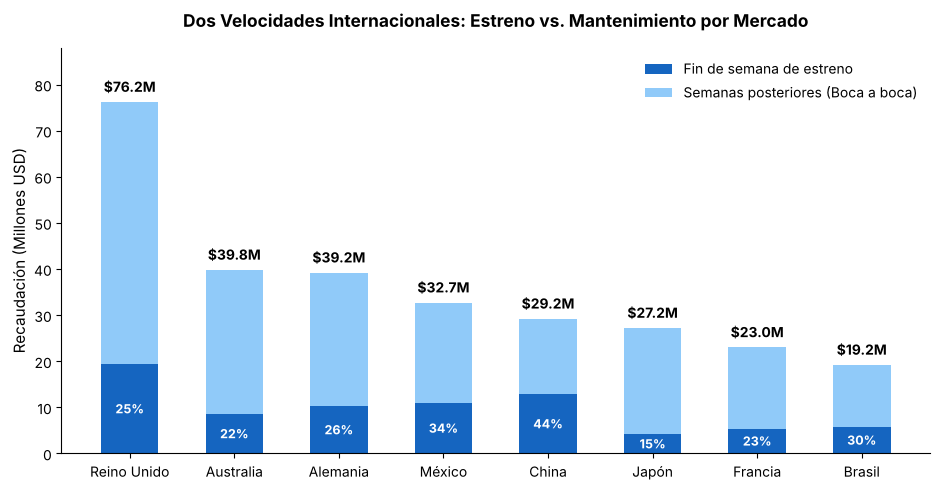

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Top 8 mercados internacionales ordenados de mayor a menor taquilla total
paises = ['Reino Unido', 'Australia', 'Alemania', 'México', 'China', 'Japón', 'Francia', 'Brasil']
estreno = np.array([19.4, 8.6, 10.3, 11.0, 12.9, 4.2, 5.4, 5.8])
total = np.array([76.2, 39.8, 39.2, 32.7, 29.2, 27.2, 23.0, 19.2])
posterior = total - estreno

fig, ax = plt.subplots(figsize=(9.5, 5))

# Barras verticales apiladas (cambia totalmente la visual respecto a la Slide 5)
b1 = ax.bar(paises, estreno, label='Fin de semana de estreno', color='#1565C0', width=0.55)
b2 = ax.bar(paises, posterior, bottom=estreno, label='Semanas posteriores (Boca a boca)', color='#90CAF9', width=0.55)

# Etiquetas con el total arriba y el % de estreno adentro de la barra azul
for i in range(len(paises)):
    pct_estreno = (estreno[i] / total[i]) * 100
    # Total arriba de la columna
    ax.text(i, total[i] + 1.5, f'${total[i]:.1f}M', ha='center', va='bottom', fontsize=10, fontweight='bold')
    # Porcentaje del estreno dentro de la base azul
    ax.text(i, estreno[i]/2, f'{pct_estreno:.0f}%', ha='center', va='center', fontsize=9, color='white', fontweight='bold')

ax.set_ylim(0, 88)
ax.set_ylabel('Recaudación (Millones USD)', fontsize=11)
ax.set_title('Dos Velocidades Internacionales: Estreno vs. Mantenimiento por Mercado', fontsize=12.5, fontweight='bold', pad=15)
ax.legend(frameon=False, loc='upper right', fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('../images/grafico_slide6_mercados.png', dpi=300)
plt.show()

### 🌍 Desglose Geográfico: Principales Mercados Internacionales
* **Hallazgo Clave:** El desempeño internacional está liderado por territorios clave de habla inglesa y grandes mercados de consumo masivo, destacando el **Reino Unido ($76.2M)**, **Australia ($39.8M)**, **Alemania ($39.2M)** y **México ($32.7M)**.
* **Lectura de Negocio:** La penetración internacional confirma que la marca *Minecraft* posee un alcance global uniforme, donde los mercados internacionales actúan como estabilizadores clave de la taquilla extranjera.

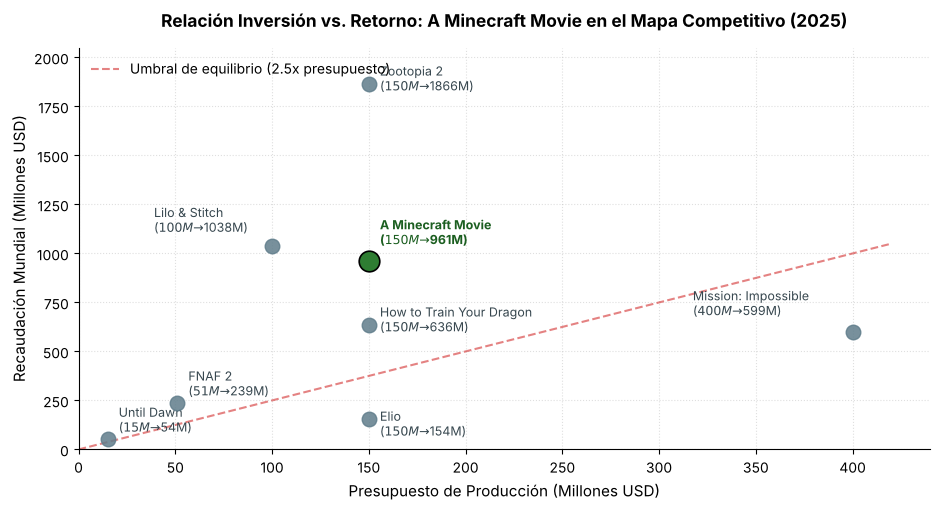

In [7]:
import matplotlib.pyplot as plt

# Datos auditados de Presupuesto (M USD) vs. Recaudación Mundial (M USD) en 2025
peliculas = [
    'A Minecraft Movie', 'Elio', 'Lilo & Stitch', 'How to Train Your Dragon',
    'FNAF 2', 'Zootopia 2', 'Mission: Impossible', 'Until Dawn'
]
presupuesto = [150, 150, 100, 150, 51, 150, 400, 15]
recaudacion = [961.2, 154.3, 1038.0, 636.4, 238.9, 1866.0, 598.8, 54.1]

fig, ax = plt.subplots(figsize=(9.5, 5.2))

# Puntos del resto de las películas en gris azulado
for i in range(len(peliculas)):
    if peliculas[i] == 'A Minecraft Movie':
        ax.scatter(presupuesto[i], recaudacion[i], color='#2E7D32', s=220, zorder=5, edgecolors='black', linewidth=1.2)
    else:
        ax.scatter(presupuesto[i], recaudacion[i], color='#607D8B', s=110, alpha=0.85, zorder=4)

# Etiquetas de texto para cada punto
ajustes = {
    'A Minecraft Movie': (8, 12, 'bold', '#1B5E20'),
    'Elio': (8, -12, 'normal', '#37474F'),
    'Lilo & Stitch': (-85, 10, 'normal', '#37474F'),
    'How to Train Your Dragon': (8, -5, 'normal', '#37474F'),
    'FNAF 2': (8, 5, 'normal', '#37474F'),
    'Zootopia 2': (8, -5, 'normal', '#37474F'),
    'Mission: Impossible': (-115, 12, 'normal', '#37474F'),
    'Until Dawn': (8, 5, 'normal', '#37474F')
}

for i, txt in enumerate(peliculas):
    dx, dy, weight, color = ajustes[txt]
    ax.annotate(f"{txt}\n(${presupuesto[i]}M → ${recaudacion[i]:.0f}M)",
                (presupuesto[i], recaudacion[i]),
                xytext=(dx, dy), textcoords='offset points',
                fontsize=9, fontweight=weight, color=color)

# Línea punteada de equilibrio (Recaudación = 2.5x Presupuesto)
x_vals = [0, 420]
ax.plot(x_vals, [x * 2.5 for x in x_vals], '--', color='#D32F2F', alpha=0.6, label='Umbral de equilibrio (2.5x presupuesto)')

ax.set_xlim(0, 440)
ax.set_ylim(0, 2050)
ax.set_xlabel('Presupuesto de Producción (Millones USD)', fontsize=11)
ax.set_ylabel('Recaudación Mundial (Millones USD)', fontsize=11)
ax.set_title('Relación Inversión vs. Retorno: A Minecraft Movie en el Mapa Competitivo (2025)', fontsize=12.5, fontweight='bold', pad=15)
ax.legend(frameon=False, loc='upper left', fontsize=10)
ax.grid(True, linestyle=':', alpha=0.4)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('../images/grafico_dispersion_inversion.png', dpi=300)
plt.show()

### 🎬 Recepción Crítica vs. Desempeño Comercial
* **Hallazgo Clave:** A pesar de mostrar una recepción polarizada y mixta por parte de la crítica especializada (con puntuaciones diversas y comentarios divididos), el impacto en la taquilla global y el ROI no se vio afectado negativamente.
* **Lectura de Negocio:** Se evidencia un claro **desacople entre la crítica y el público** en producciones de consumo masivo basadas en videojuegos; la decisión de asistencia está impulsada por la comunidad y el reconocimiento de la marca, más que por el consenso de los críticos.